# 01 · Análisis exploratorio y preprocesamiento

**Proyecto A — Detección temprana de conversaciones que van a necesitar una persona.**

Pregunta: con los primeros 4 mensajes de una conversación que empezó la atención automática
(todos anteriores a cualquier intervención humana), ¿podemos anticipar si va a necesitar a una
persona del equipo?

Este notebook cubre los puntos **3.2 (preprocesamiento)** y **3.3 (EDA)** del enunciado y deja
fijadas las decisiones que usan los notebooks de modelado:

1. Calidad de los datos: tipos, faltantes, duplicados, atípicos.
2. La variable objetivo y el peso de la empresa dominante (E09).
3. Cobertura temporal y cambio en la mezcla de empresas.
4. Relación de cada variable con la etiqueta.
5. `ai_chars_mean` como posible huella de la empresa.
6. Preprocesamiento final y esquemas de validación.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load, build_features, time_split, TARGET, DOMINANT

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

# Two-class palette: blue = resolved by automation, orange = needed a person.
C0, C1, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
sns.set_theme(style="white", rc={"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": INK,
                                 "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                                 "grid.color": "#e6e5e1", "figure.dpi": 110, "font.size": 10})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

def wilson(k, n, z=1.96):
    # Confidence interval for a proportion that behaves well with small n (the sparse flags).
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

df = load(ROOT / "data" / "orvyz_conversaciones_riesgo.csv")
df.shape

(62788, 26)

## 1. Vista general y calidad de los datos

In [2]:
df.head()

,empresa,cliente,fecha,channel,hour_local,dow,w_customer_msgs,w_ai_msgs,cust_chars_mean,cust_chars_max,cust_question_marks,cust_repeats,media_image,media_audio,media_document,media_other,first_ai_reply_s,cust_gap_mean_s,ai_chars_mean,ai_no_info,cust_asks_human,cust_negative_words,prior_conversations,prior_needed_human,needed_human,mes
0,E09,U001163,2026-10-07,whatsapp,8,3,2,2,14.0,24,0,0,0,0,0,0,5.1,9.0,591.5,0,0,0,60,57,1,2026-10
1,E09,U003376,2026-08-04,whatsapp,12,2,2,2,5.5,7,0,0,0,0,0,0,6.6,15.0,591.5,0,0,0,22,19,1,2026-08
2,E09,U002162,2026-07-29,whatsapp,11,3,2,2,10.5,15,0,0,0,0,0,0,7.0,11.0,591.5,0,0,0,43,42,1,2026-07
3,E09,U000661,2026-09-03,whatsapp,15,4,2,2,7.5,14,0,0,0,0,0,0,11.3,17.0,591.5,0,0,0,44,42,1,2026-09
4,E09,U002381,2026-08-03,whatsapp,16,1,2,2,7.0,8,0,0,0,0,0,0,6.9,21.0,591.5,0,0,0,3,3,1,2026-08


In [3]:
resumen = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes": df.isna().sum(),
                        "% faltantes": (df.isna().mean() * 100).round(2), "valores distintos": df.nunique()})
print("Filas duplicadas:", df.duplicated().sum())
resumen

Filas duplicadas: 0


,tipo,faltantes,% faltantes,valores distintos
empresa,str,0,0.00,12
cliente,str,0,0.00,4347
fecha,datetime64[us],0,0.00,309
channel,str,0,0.00,2
hour_local,int64,0,0.00,24
dow,int64,0,0.00,7
w_customer_msgs,int64,0,0.00,4
w_ai_msgs,int64,0,0.00,4
cust_chars_mean,float64,0,0.00,1201
cust_chars_max,int64,0,0.00,618


**Faltantes.** Solo tres columnas tienen vacíos y los dos patrones tienen explicación:

- `first_ai_reply_s` y `ai_chars_mean` están vacías **en las mismas 321 filas**. En todas, la IA no
  escribió dentro de la ventana, porque los 4 mensajes son del cliente.
- `cust_gap_mean_s` está vacía cuando el cliente escribió **un solo mensaje** (no hay intervalo que medir).

Como estos vacíos significan algo, no se imputan a ciegas: se crean los indicadores `no_ai_reply`
y `single_customer_msg`, y el valor numérico se imputa con la mediana **ajustada en entrenamiento**.

In [4]:
sin_ia = df[df.first_ai_reply_s.isna()]
print("Filas sin respuesta automática:", len(sin_ia),
      "| igual vacío en ai_chars_mean:", df.ai_chars_mean.isna().eq(df.first_ai_reply_s.isna()).all())
print("w_ai_msgs en esas filas:", sin_ia.w_ai_msgs.unique(), "| w_customer_msgs:", sin_ia.w_customer_msgs.unique())
print("Tasa de 'necesitó persona' cuando la IA no alcanzó a responder:", round(sin_ia[TARGET].mean(), 2),
      "vs", round(df[TARGET].mean(), 2), "general")
print("cust_gap_mean_s vacío ⇔ un solo mensaje del cliente:",
      df.cust_gap_mean_s.isna().eq(df.w_customer_msgs.eq(1)).all())

Filas sin respuesta automática: 321 | igual vacío en ai_chars_mean: True
w_ai_msgs en esas filas: [0] | w_customer_msgs: [4]
Tasa de 'necesitó persona' cuando la IA no alcanzó a responder: 0.86 vs 0.92 general
cust_gap_mean_s vacío ⇔ un solo mensaje del cliente: True


## 2. La variable objetivo y la empresa dominante

In [5]:
por_emp = (df.groupby("empresa")[TARGET].agg(n="size", tasa="mean").sort_values("n"))
por_emp["% filas"] = (por_emp.n / len(df) * 100).round(1)
print(f"Positivos en todo el conjunto: {df[TARGET].mean():.1%}")
por_emp.round(3)

Positivos en todo el conjunto: 91.7%


,n,tasa,% filas
empresa,,,
E03,95,0.074,0.2
E11,115,0.391,0.2
E02,132,0.871,0.2
E05,170,0.429,0.3
E10,194,0.835,0.3
E04,247,0.526,0.4
E06,594,0.340,0.9
E08,669,0.874,1.1
E12,874,0.598,1.4


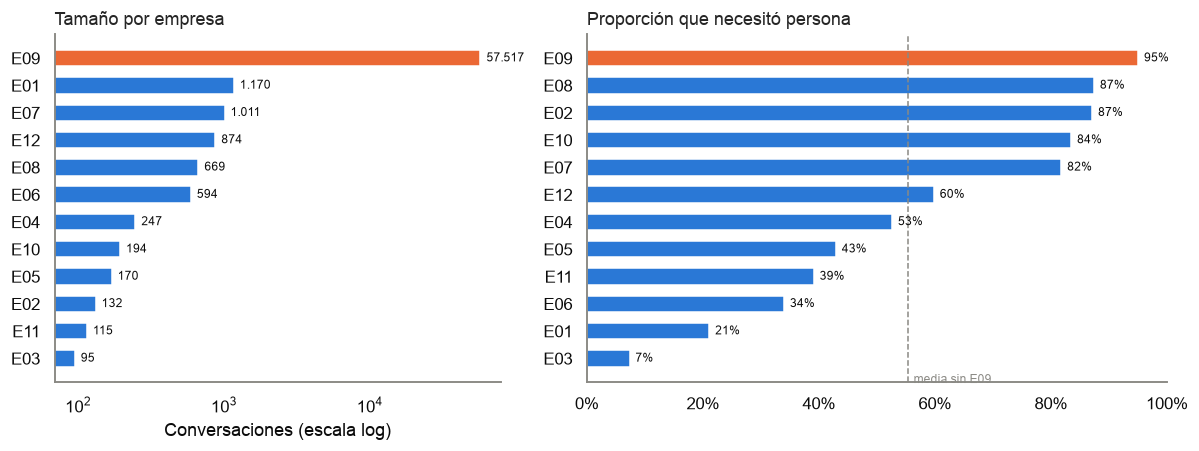

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
o = por_emp.sort_values("n")
a1.barh(o.index, o.n, color=[C1 if e == DOMINANT else C0 for e in o.index], height=0.6)
a1.set_xscale("log"); a1.set_xlabel("Conversaciones (escala log)"); a1.set_title("Tamaño por empresa", loc="left")
for y, v in enumerate(o.n): a1.text(v * 1.1, y, f"{v:,}".replace(",", "."), va="center", fontsize=8, color=INK)
o2 = por_emp.sort_values("tasa")
a2.barh(o2.index, o2.tasa, color=[C1 if e == DOMINANT else C0 for e in o2.index], height=0.6)
a2.axvline(df[df.empresa != DOMINANT][TARGET].mean(), color=MUTED, ls="--", lw=1)
a2.text(df[df.empresa != DOMINANT][TARGET].mean() + 0.01, -0.9, "media sin E09", color=MUTED, fontsize=8)
a2.set_xlim(0, 1); a2.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
a2.set_title("Proporción que necesitó persona", loc="left")
for y, v in enumerate(o2.tasa): a2.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8, color=INK)
fig.tight_layout(); save(fig, "01_empresas"); plt.show()

**Decisión: el conjunto principal excluye a E09.**

- E09 aporta el **92 %** de las filas y en ella interviene una persona en el **95 %** de los casos,
  porque su operación es mixta por diseño. Con E09 adentro, un modelo que prediga siempre 1 acierta
  casi siempre, y las métricas reflejan la operación de E09, no el problema.
- Sin E09 quedan unas 5.300 conversaciones con **55 % de positivos**, prácticamente balanceadas.
  Ese es el conjunto donde la pregunta tiene sentido.
- La proporción va de 7 % a 95 % según la empresa, así que **la empresa por sí sola predice mucho**.
  Un modelo que sirva para negocios nuevos no puede apoyarse en ella: por eso se valida también
  dejando empresas fuera.

E09 se conserva como escenario secundario (se reporta, pero no guía decisiones).

In [7]:
rest = df[df.empresa != DOMINANT].copy()
print(f"Sin {DOMINANT}: {len(rest):,} filas, {rest.cliente.nunique():,} clientes, "
      f"{rest.empresa.nunique()} empresas, positivos {rest[TARGET].mean():.1%}")
print("Clientes que aparecen en más de una empresa:", (rest.groupby("cliente").empresa.nunique() > 1).sum())

Sin E09: 5,271 filas, 3,507 clientes, 11 empresas, positivos 55.3%
Clientes que aparecen en más de una empresa: 0


## 3. Cobertura temporal y cambio de mezcla

In [8]:
mes = rest.groupby("mes")[TARGET].agg(n="size", tasa="mean")
mes.T.round(2)

mes,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
n,6.00,46.0,61.00,74.00,52.00,46.00,187.00,19.00,21.00,39.00,2.0,73.00,104.00,215.00,1861.00,2465.00
tasa,0.67,0.8,0.92,0.92,0.94,0.87,0.46,0.79,0.86,0.92,0.5,0.71,0.68,0.42,0.64,0.44


Antes de julio de 2026 casi no había atención automática (de 2 a 187 conversaciones al mes fuera
de E09). **El periodo útil es julio–octubre de 2026**, y la separación temporal queda así:
entrenar con todo lo anterior al 1 de octubre y probar con octubre.

La tasa de positivos baja de 64 % en septiembre a 44 % en octubre. La pregunta es si cambió el
comportamiento o cambió la mezcla de empresas.

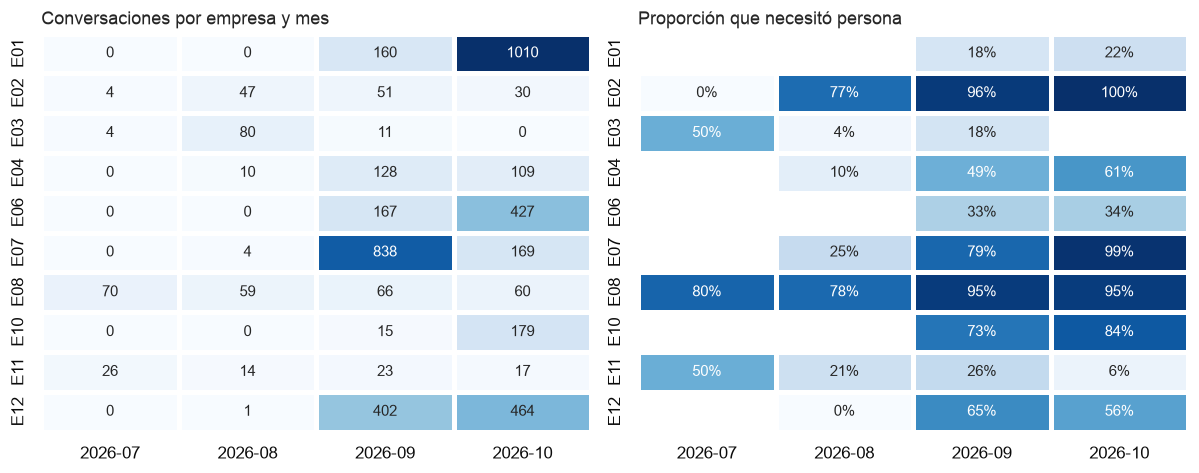

Sep real 64% | Oct real 44% | Oct esperada con tasas de sep y mezcla de oct: 42%


In [9]:
r4 = rest[rest.mes >= "2026-07"]
filas = pd.crosstab(r4.empresa, r4.mes)
tasas = r4.pivot_table(index="empresa", columns="mes", values=TARGET, aggfunc="mean")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4))
sns.heatmap(filas, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a1, linewidths=2, linecolor="white")
a1.set_title("Conversaciones por empresa y mes", loc="left"); a1.set_xlabel(""); a1.set_ylabel("")
sns.heatmap(tasas, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a2,
            linewidths=2, linecolor="white")
a2.set_title("Proporción que necesitó persona", loc="left"); a2.set_xlabel(""); a2.set_ylabel("")
fig.tight_layout(); save(fig, "02_empresa_mes"); plt.show()

# Expected October rate if each company kept its September rate: isolates the mix effect.
sep, oct_ = r4[r4.mes == "2026-09"], r4[r4.mes == "2026-10"]
tasa_sep = sep.groupby("empresa")[TARGET].mean()
peso_oct = oct_.empresa.value_counts(normalize=True)
esperada = (peso_oct * tasa_sep.reindex(peso_oct.index).fillna(sep[TARGET].mean())).sum()
print(f"Sep real {sep[TARGET].mean():.0%} | Oct real {oct_[TARGET].mean():.0%} | "
      f"Oct esperada con tasas de sep y mezcla de oct: {esperada:.0%}")

**La caída se explica casi entera por la mezcla.** E01 pasa de 160 a 1.010 conversaciones en octubre
y es de las empresas con menos intervención humana (22 %). Si cada empresa conservara su tasa de
septiembre, octubre tendría casi la misma proporción que se observó.

Consecuencias para el modelado:

- La prueba temporal mide **dos cosas a la vez**: generalizar en el tiempo y soportar un cambio en la
  proporción de positivos. Hay que reportarla junto con métricas por empresa.
- La **calibración** puede verse afectada: si el modelo no reconoce el cambio de mezcla, una
  probabilidad aprendida con 64 % de positivos sobreestimaría el riesgo en octubre. Queda como
  hipótesis para el notebook 02, que la pone a prueba (resultado: el modelo sí sigue el cambio de
  mezcla y no hace falta corregir).
- El **umbral** de decisión no debe fijarse en 0,5 por defecto. Se elige en validación con un
  criterio de negocio, por ejemplo recall ≥ 0,80.

## 4. Canal, hora y día

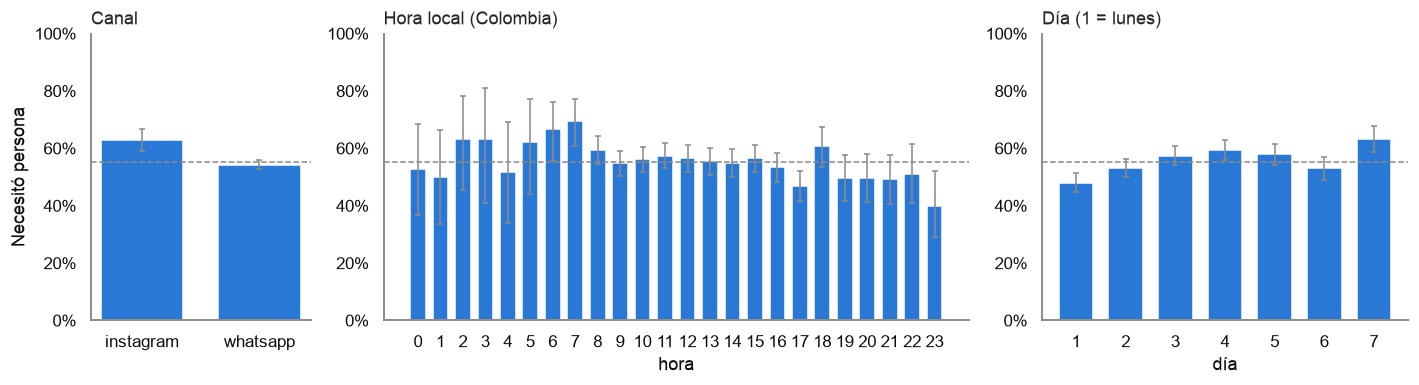

            mean  size
channel               
instagram  0.629   606
whatsapp   0.543  4665


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [0.6, 1.6, 1]})
def tasa_bar(ax, g, title, xlabel):
    t = rest.groupby(g)[TARGET].agg(["mean", "size"])
    ci = np.array([wilson(m * n, n) for m, n in zip(t["mean"], t["size"])])
    ax.bar(t.index.astype(str), t["mean"], color=C0, width=0.7)
    ax.errorbar(t.index.astype(str), t["mean"], yerr=[t["mean"] - ci[:, 0], ci[:, 1] - t["mean"]],
                fmt="none", ecolor=MUTED, lw=1, capsize=2)
    ax.axhline(rest[TARGET].mean(), color=MUTED, ls="--", lw=1)
    ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel)
    return t
t_canal = tasa_bar(axs[0], "channel", "Canal", "")
t_hora = tasa_bar(axs[1], "hour_local", "Hora local (Colombia)", "hora")
t_dia = tasa_bar(axs[2], "dow", "Día (1 = lunes)", "día")
axs[0].set_ylabel("Necesitó persona"); fig.tight_layout(); save(fig, "03_canal_hora_dia"); plt.show()
print(t_canal.round(3))

Las barras de error son intervalos de Wilson al 95 %, porque varias horas de la madrugada tienen
muy pocas conversaciones. La línea punteada es la media sin E09 (55 %).

- **Canal:** Instagram tiene algo más de intervención (63 % contra 54 %), pero solo aporta unas
  600 filas y depende de qué empresas lo usan.
- **Hora y día:** hay variación, pero los intervalos se solapan mucho. Son señales débiles, que
  conviene conservar porque son baratas y pueden interactuar con otras: fuera de horario puede haber
  menos personas disponibles.

## 5. Variables numéricas: distribución y relación con la etiqueta

In [11]:
num = ["w_customer_msgs", "w_ai_msgs", "cust_chars_mean", "cust_chars_max", "cust_question_marks",
       "first_ai_reply_s", "cust_gap_mean_s", "ai_chars_mean", "prior_conversations", "prior_needed_human"]
rest[num].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(1)

,count,mean,std,min,1%,25%,50%,75%,99%,max
w_customer_msgs,5271.0,2.1,0.5,1.0,1.0,2.0,2.0,2.0,4.0,4.0
w_ai_msgs,5271.0,1.9,0.5,0.0,0.0,2.0,2.0,2.0,3.0,3.0
cust_chars_mean,5271.0,57.0,88.4,1.0,4.0,13.5,25.5,56.5,399.8,1292.3
cust_chars_max,5271.0,91.7,143.8,1.0,4.0,20.0,34.0,79.0,674.6,2451.0
cust_question_marks,5271.0,0.3,0.6,0.0,0.0,0.0,0.0,1.0,2.0,10.0
first_ai_reply_s,5198.0,123.9,5399.0,-53240.7,3.5,5.8,12.2,19.3,82.2,337729.0
cust_gap_mean_s,4726.0,4856.3,71566.8,0.0,0.4,15.0,34.0,91.4,83679.8,3900630.8
ai_chars_mean,5198.0,462.4,528.6,3.0,35.5,131.1,266.0,689.0,1834.5,4530.0
prior_conversations,5271.0,3.3,9.1,0.0,0.0,0.0,0.0,2.0,45.3,97.0
prior_needed_human,5271.0,1.0,2.7,0.0,0.0,0.0,0.0,0.0,14.0,27.0


**Atípicos.** Las colas son muy largas: hay respuestas automáticas de más de 4.500 caracteres
(los menús cuentan su contenido estructurado), intervalos entre mensajes de días y tiempos de
primera respuesta negativos (47 filas, en las que el bot escribió primero). No son errores, son
parte del fenómeno. Por eso **no se eliminan**: se transforman con un logaritmo con signo
`sign(x)·log(1+|x|)`, que comprime la cola y conserva el orden y los negativos. Los árboles no lo
necesitan, pero kNN, SVM y la regresión logística sí.

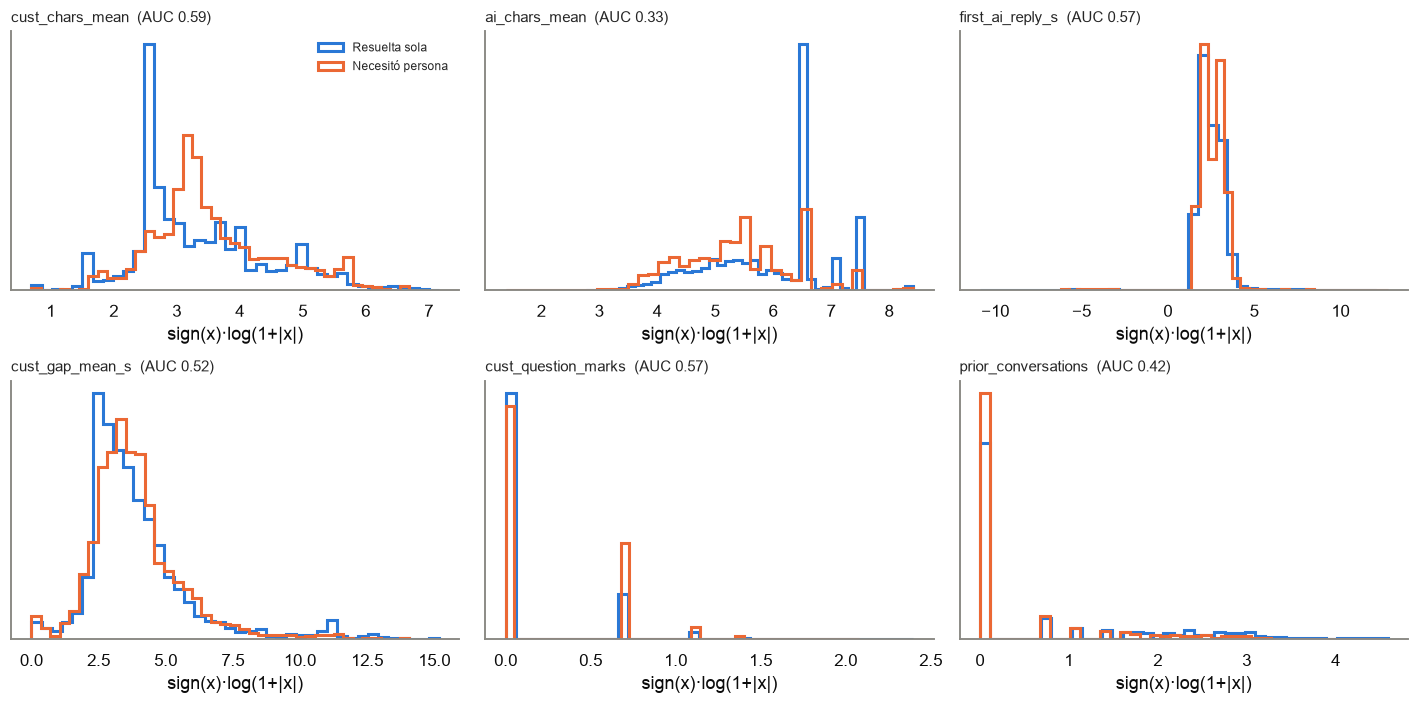

In [12]:
from features import signed_log
cols = ["cust_chars_mean", "ai_chars_mean", "first_ai_reply_s", "cust_gap_mean_s", "cust_question_marks", "prior_conversations"]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axs.flat, cols):
    for y, col, lab in [(0, C0, "Resuelta sola"), (1, C1, "Necesitó persona")]:
        v = signed_log(rest.loc[rest[TARGET] == y, c].dropna())
        ax.hist(v, bins=40, density=True, histtype="step", lw=2, color=col, label=lab)
    v = rest[c].dropna(); auc = roc_auc_score(rest.loc[v.index, TARGET], v)
    ax.set_title(f"{c}  (AUC {auc:.2f})", loc="left", fontsize=10); ax.set_xlabel("sign(x)·log(1+|x|)")
    ax.set_yticks([])
axs[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "04_distribuciones"); plt.show()

El AUC del título usa la variable cruda como puntaje. 0,5 es no separar nada, y por debajo de 0,5
significa que la relación va al revés: valores altos, menos intervención.

- `ai_chars_mean` es la que más separa sola. **Respuestas automáticas largas se asocian a menos
  intervención humana.** La sección 6 revisa si eso es comportamiento o identidad de la empresa.
- `prior_conversations`: los clientes que vuelven necesitan menos a una persona.
- `cust_question_marks`: más preguntas, más intervención.

### Clientes que vuelven

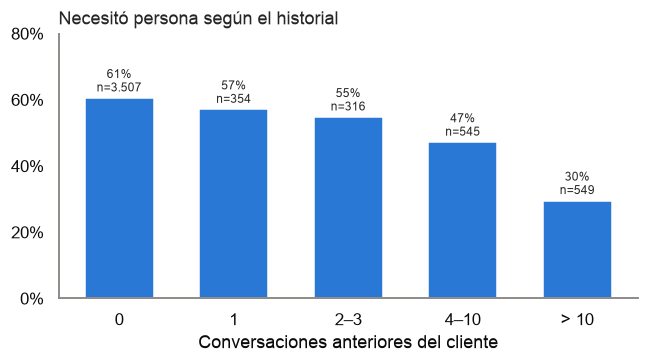

Con historial: AUC de prior_needed_human / prior_conversations = 0.842


In [13]:
b = pd.cut(rest.prior_conversations, [-1, 0, 1, 3, 10, 1000], labels=["0", "1", "2–3", "4–10", "> 10"])
h = rest.groupby(b, observed=True)[TARGET].agg(n="size", tasa="mean")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(h.index.astype(str), h.tasa, color=C0, width=0.6)
for x, (n, t) in enumerate(zip(h.n, h.tasa)): ax.text(x, t + 0.02, f"{t:.0%}\nn={n:,}".replace(",", "."), ha="center", fontsize=8)
ax.set_ylim(0, 0.8); ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Conversaciones anteriores del cliente"); ax.set_title("Necesitó persona según el historial", loc="left")
fig.tight_layout(); save(fig, "05_historial"); plt.show()

con_hist = rest[rest.prior_conversations > 0]
print("Con historial: AUC de prior_needed_human / prior_conversations =",
      round(roc_auc_score(con_hist[TARGET], con_hist.prior_needed_human / con_hist.prior_conversations), 3))

Hay un gradiente claro: 60 % sin historial contra 28 % con más de 10 conversaciones anteriores.
Para los que tienen historial, **la proporción de sus conversaciones pasadas que necesitaron
persona** es buena señal, y se agrega como variable `prior_human_rate`.

*Cuidado con la fuga:* el historial solo cuenta conversaciones **anteriores** del mismo cliente.
Si una conversación anterior seguía abierta cuando empezó la actual, su etiqueta podría no
conocerse aún en producción. Es un caso de borde que se menciona como limitación.

### Señales escasas

In [14]:
esc = ["cust_repeats", "media_image", "media_audio", "media_document", "media_other",
       "ai_no_info", "cust_asks_human", "cust_negative_words"]
rows = []
for c in esc:
    on = rest[rest[c] > 0]; lo, hi = wilson(on[TARGET].sum(), len(on))
    rows.append({"variable": c, "% ceros": (rest[c] == 0).mean(), "filas > 0": len(on),
                 "tasa si > 0": on[TARGET].mean(), "IC 95 %": f"{lo:.0%}–{hi:.0%}"})
pd.DataFrame(rows).set_index("variable").style.format({"% ceros": "{:.1%}", "tasa si > 0": "{:.0%}"})

,% ceros,filas > 0,tasa si > 0,IC 95 %
variable,,,,
cust_repeats,98.2%,94,39%,30%–49%
media_image,93.8%,325,61%,55%–66%
media_audio,98.4%,82,84%,75%–90%
media_document,99.3%,39,18%,9%–33%
media_other,97.9%,111,59%,49%–67%
ai_no_info,98.6%,75,60%,49%–70%
cust_asks_human,99.4%,30,67%,49%–81%
cust_negative_words,99.7%,14,50%,27%–73%


Entre 94 % y 100 % de ceros. Es esperable: la ventana es corta (4 mensajes) y muchos clientes
tocan botones de menú en vez de escribir. Con tan pocos casos, los intervalos son anchos y la
mayoría se solapan con la media del 55 %.

**Decisión:** se conservan porque son interpretables y útiles en la interfaz ("el cliente pidió un
asesor"), y los adjuntos se agregan además en `has_media`. Ningún modelo puede aprender mucho de
16 a 75 casos, y así se reporta. Si hiciera falta más señal, se puede regenerar el conjunto con una
ventana de hasta 8 mensajes.

## 6. ¿`ai_chars_mean` mide comportamiento o identidad de la empresa?

Cada empresa configura su agente de forma distinta. Algunas responden con menús largos y otras con
frases cortas. Si el largo de las respuestas solo identifica a la empresa, el modelo estaría
aprendiendo "esta es E01, que casi no escala", lo que no sirve para empresas nuevas.

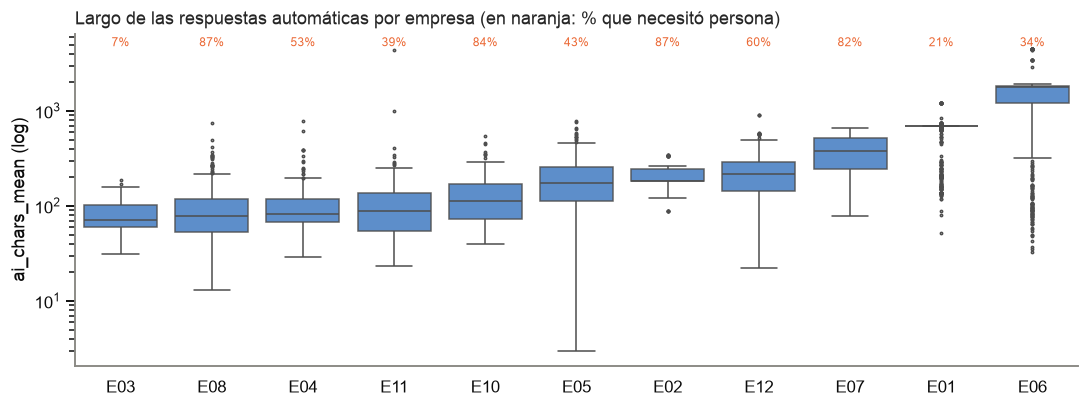

In [15]:
orden = rest.groupby("empresa").ai_chars_mean.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.boxplot(data=rest, x="empresa", y="ai_chars_mean", order=orden, color=C0, fliersize=1.5,
            linewidth=1, ax=ax, boxprops={"alpha": .85})
ax.set_yscale("log"); ax.set_ylabel("ai_chars_mean (log)"); ax.set_xlabel("")
tx = ax.twinx(); tx.set_yticks([]); tx.spines[:].set_visible(False)
for x, e in enumerate(orden):
    ax.text(x, 4800, f"{por_emp.loc[e, 'tasa']:.0%}", ha="center", fontsize=8, color=C1)
ax.set_title("Largo de las respuestas automáticas por empresa (en naranja: % que necesitó persona)", loc="left")
fig.tight_layout(); save(fig, "06_ai_chars_empresa"); plt.show()

In [16]:
# How much of the company identity does this single feature carry?
cv = StratifiedKFold(5, shuffle=True, random_state=0)
Xa = rest[["ai_chars_mean"]].fillna(-1)
acc = cross_val_score(DecisionTreeClassifier(max_depth=6, random_state=0), Xa, rest.empresa, cv=cv).mean()
print(f"Adivinar la empresa (11 clases) solo con ai_chars_mean: exactitud {acc:.0%} "
      f"(clase mayoritaria: {rest.empresa.value_counts(normalize=True).max():.0%})")

auc_pooled = roc_auc_score(rest.dropna(subset=['ai_chars_mean'])[TARGET], -rest.ai_chars_mean.dropna())
dentro = {e: roc_auc_score(g[TARGET], -g.ai_chars_mean) for e, g in rest.dropna(subset=["ai_chars_mean"]).groupby("empresa")
          if g[TARGET].nunique() > 1 and len(g) >= 50}
print(f"AUC de -ai_chars_mean mezclando empresas: {auc_pooled:.2f}")
print("AUC dentro de cada empresa:", {k: round(v, 2) for k, v in dentro.items()})
print(f"Promedio dentro de empresa: {np.mean(list(dentro.values())):.2f}")

Adivinar la empresa (11 clases) solo con ai_chars_mean: exactitud 67% (clase mayoritaria: 22%)
AUC de -ai_chars_mean mezclando empresas: 0.67
AUC dentro de cada empresa: {'E01': 0.45, 'E02': 0.4, 'E03': 0.46, 'E04': 0.57, 'E05': 0.53, 'E06': 0.56, 'E07': 0.59, 'E08': 0.52, 'E10': 0.51, 'E11': 0.56, 'E12': 0.51}
Promedio dentro de empresa: 0.51


**Lectura.** Mezclando empresas, `-ai_chars_mean` tiene AUC 0,67, pero **dentro de cada empresa
el AUC va de 0,40 a 0,59 y promedia 0,51, es decir, azar**. En algunas empresas la relación incluso
se invierte. Además, con esa sola variable se adivina la empresa en el 67 % de los
casos (la clase mayoritaria es el 22 %). Es una **huella de la empresa**: separa empresas, no
conversaciones. Dentro de un mismo negocio, que la respuesta sea larga o corta no dice nada sobre
si va a hacer falta una persona.

Para no sacar conclusiones de una sola variable, la misma prueba se hace con todas: AUC
mezclando empresas contra el AUC promedio dentro de cada empresa (ponderado por tamaño, empresas
con ≥ 50 filas y ambas clases). Una variable útil para negocios nuevos debe conservar su AUC
dentro de las empresas.

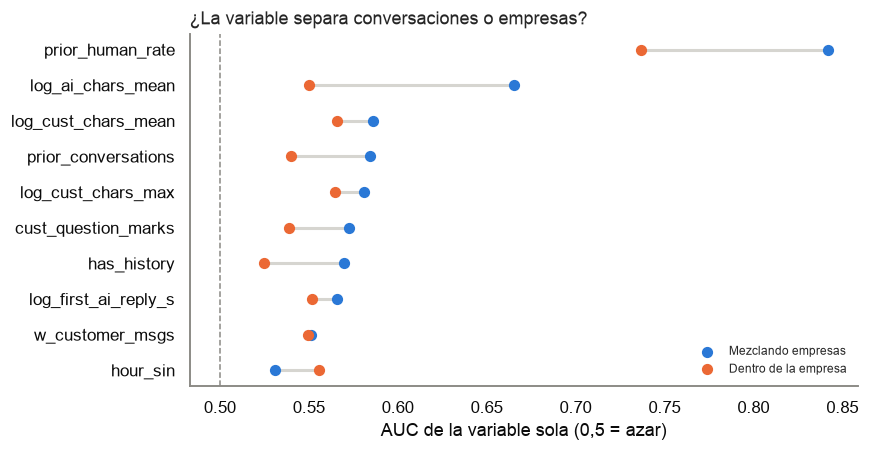

,mezclando empresas,dentro de la empresa
variable,,
hour_sin,0.53,0.56
w_customer_msgs,0.55,0.55
log_first_ai_reply_s,0.57,0.55
has_history,0.57,0.52
cust_question_marks,0.57,0.54
log_cust_chars_max,0.58,0.56
prior_conversations,0.58,0.54
log_cust_chars_mean,0.59,0.57
log_ai_chars_mean,0.67,0.55


In [17]:
def auc_dir(y, s):
    a = roc_auc_score(y, s); return max(a, 1 - a)   # direction-agnostic separation
feats = build_features(rest).drop(columns=[f"dow_{d}" for d in range(1, 8)])
filas_ = []
for c in feats.columns:
    v = feats[c]; ok = v.notna()
    if v[ok].nunique() < 2: continue
    pooled = auc_dir(rest.loc[ok, TARGET], v[ok])
    w = [(len(g), auc_dir(g[TARGET], v[g.index])) for e, g in rest[ok].groupby("empresa")
         if g[TARGET].nunique() > 1 and len(g) >= 50 and v[g.index].nunique() > 1]
    within = np.average([a for _, a in w], weights=[n for n, _ in w]) if w else np.nan
    filas_.append({"variable": c, "mezclando empresas": pooled, "dentro de la empresa": within})
sep_tab = pd.DataFrame(filas_).set_index("variable").sort_values("mezclando empresas")
sep_tab = sep_tab[sep_tab["mezclando empresas"] > 0.53]

fig, ax = plt.subplots(figsize=(8, 0.32 * len(sep_tab) + 1))
yy = np.arange(len(sep_tab))
ax.hlines(yy, sep_tab["dentro de la empresa"], sep_tab["mezclando empresas"], color="#d6d5d0", lw=2)
ax.scatter(sep_tab["mezclando empresas"], yy, color=C0, s=40, zorder=3, label="Mezclando empresas")
ax.scatter(sep_tab["dentro de la empresa"], yy, color=C1, s=40, zorder=3, label="Dentro de la empresa")
ax.set_yticks(yy, sep_tab.index); ax.axvline(0.5, color=MUTED, ls="--", lw=1)
ax.set_xlabel("AUC de la variable sola (0,5 = azar)"); ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("¿La variable separa conversaciones o empresas?", loc="left")
fig.tight_layout(); save(fig, "06b_auc_dentro_empresa"); plt.show()
sep_tab.round(2)

- **`ai_chars_mean` es el caso más claro de huella:** es la que más pierde, de 0,67 a 0,55, al
  nivel de variables débiles como la hora.
- **El historial del cliente sí es señal real.** `prior_human_rate` (calculada solo para clientes
  con historial) pasa de 0,84 a 0,74 y sigue siendo de lejos la mejor dentro de cada empresa: un
  cliente que antes necesitó a una persona tiende a volver a necesitarla.
- El resto (largo de los mensajes del cliente, preguntas, tiempo de respuesta, hora) queda entre
  0,52 y 0,57, tanto mezclando empresas como dentro de ellas: señales débiles pero honestas.

**Decisión para el modelado:**
- entrenar y reportar **con y sin** `ai_chars_mean`. Se espera que ayude en la prueba temporal,
  donde las empresas son las mismas, y que no ayude, o incluso estorbe, con empresas no vistas;
- el modelo que se despliegue para empresas nuevas no debe depender de ella;
- en SHAP, mostrar que su efecto coincide con la identidad de la empresa.

## 7. Correlaciones entre variables

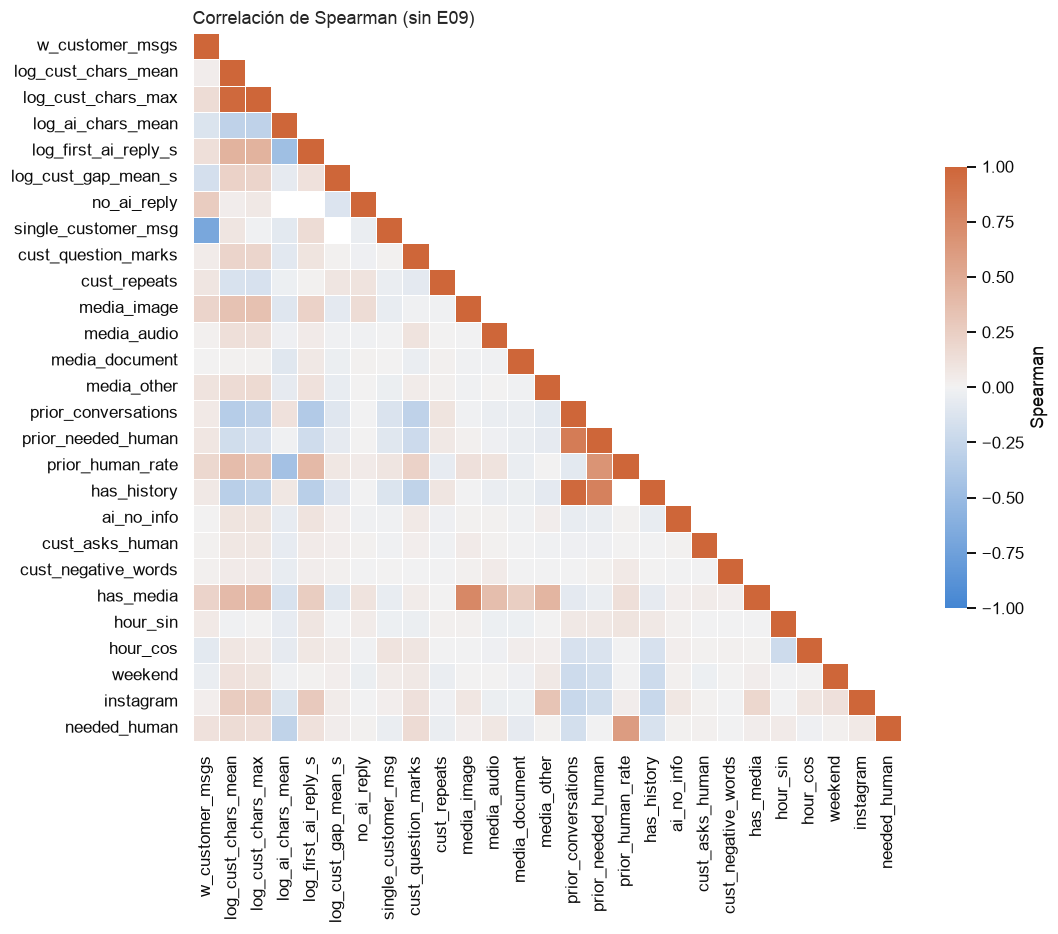

Pares con |ρ| > 0,7:
has_history          prior_conversations    0.97
log_cust_chars_max   log_cust_chars_mean    0.97
prior_conversations  prior_needed_human     0.84
has_history          prior_needed_human     0.80
media_image          has_media              0.76


In [18]:
X_eda = build_features(rest)
corr = pd.concat([X_eda, rest[TARGET]], axis=1).drop(columns=[f"dow_{d}" for d in range(1, 8)]).corr("spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
mask = np.triu(np.ones_like(corr, bool), 1)
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(250, 25, s=80, l=55, as_cmap=True), center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .6, "label": "Spearman"}, ax=ax)
ax.set_title("Correlación de Spearman (sin E09)", loc="left"); fig.tight_layout(); save(fig, "07_correlaciones"); plt.show()
alta = corr.where(~np.eye(len(corr), dtype=bool)).abs().stack().sort_values(ascending=False)
alta = alta[alta > 0.7].iloc[::2]
print("Pares con |ρ| > 0,7:"); print(alta.round(2).to_string())

Las parejas muy correlacionadas son esperables por construcción (`cust_chars_mean` con
`cust_chars_max`, `prior_conversations` con `prior_needed_human` y `has_history`, `has_media` con
`media_image`). Mensajes del cliente y de la IA en la ventana suman 4, así que son la misma
información y solo se conserva `w_customer_msgs`; el caso "la IA no respondió" ya queda en
`no_ai_reply`. Para los árboles no es problema. En la regresión logística se
controla con regularización L2. SHAP reparte la importancia entre variables correlacionadas, y hay
que tenerlo en cuenta al leerlo.

## 8. Preprocesamiento final

La función `build_features` (en `src/features.py`) solo hace transformaciones **fila a fila**, sin
estadísticas del conjunto, así que no puede filtrar información de la prueba:

| Grupo | Transformación |
|---|---|
| Largos y tiempos | `sign(x)·log(1+|x|)` |
| Conteos (preguntas, repeticiones, adjuntos, historial) | `log(1+x)` |
| Mensajes de la IA en la ventana | se descarta (`= 4 − w_customer_msgs`) |
| Faltantes informativos | `no_ai_reply`, `single_customer_msg` |
| Historial | `prior_human_rate`, `has_history` |
| Adjuntos | `has_media` |
| Hora | seno y coseno (las 23 h quedan junto a las 0 h) |
| Día | one-hot + `weekend` |
| Canal | `instagram` (0/1) |

Lo que sí se aprende de los datos va dentro de un `Pipeline` de sklearn y se ajusta **solo con
entrenamiento**: imputación con la mediana (`prior_human_rate` y los vacíos de largos y tiempos) y
escalado estándar para kNN, SVM y regresión logística.

**Desbalance:** sin E09 hay 55/45, así que no hace falta sobremuestrear. Se usa
`class_weight="balanced"` donde aplique y el umbral se elige por criterio de negocio.

In [19]:
X = build_features(rest); y = rest[TARGET]
print(X.shape); X.describe().T[["mean", "min", "max"]].round(2)

(5271, 33)


,mean,min,max
w_customer_msgs,2.06,1.00,4.00
log_cust_chars_mean,3.46,0.69,7.16
log_cust_chars_max,3.84,0.69,7.80
log_ai_chars_mean,5.64,1.39,8.42
log_first_ai_reply_s,2.51,-10.88,12.73
log_cust_gap_mean_s,3.91,0.00,15.18
no_ai_reply,0.01,0.00,1.00
single_customer_msg,0.10,0.00,1.00
cust_question_marks,0.20,0.00,2.40
cust_repeats,0.01,0.00,1.39


## 9. Esquemas de validación y control de fuga

In [20]:
tr, te = time_split(rest)
comp = set(tr.cliente) & set(te.cliente)
print(f"Temporal → entrenamiento {len(tr):,} (pos {tr[TARGET].mean():.0%}) | prueba {len(te):,} (pos {te[TARGET].mean():.0%})")
print(f"Clientes en ambos lados: {len(comp):,} ({te.cliente.isin(comp).mean():.0%} de las filas de prueba)")
nuevos = te[~te.cliente.isin(comp)]
print(f"Prueba solo con clientes nuevos: {len(nuevos):,} filas (pos {nuevos[TARGET].mean():.0%})")
print("Empresas en prueba que no están en entrenamiento:", sorted(set(te.empresa) - set(tr.empresa)))

Temporal → entrenamiento 2,806 (pos 65%) | prueba 2,465 (pos 44%)
Clientes en ambos lados: 120 (36% de las filas de prueba)
Prueba solo con clientes nuevos: 1,577 filas (pos 54%)
Empresas en prueba que no están en entrenamiento: []


**Tres esquemas, cada uno responde una pregunta distinta:**

1. **Temporal (resultado principal):** entrenar con todo lo anterior a octubre y probar con
   octubre. Es lo que pasaría en producción. Que un cliente aparezca en ambos lados es **legítimo
   aquí**: en producción el modelo también ve clientes que vuelven, y su pasado entra solo por las
   variables de historial. Aun así, se reporta además la métrica **solo con clientes nuevos** para
   mostrar que el resultado no depende de recordar clientes.
2. **Ajuste de hiperparámetros:** dentro del entrenamiento, `StratifiedGroupKFold` agrupando por
   **cliente**, para que las conversaciones de un mismo cliente no queden en entrenamiento y en
   validación a la vez.
3. **Empresas no vistas:** `LeaveOneGroupOut` por empresa. Mide si el modelo sirve para un negocio
   nuevo. Es la prueba más difícil, y la línea base da ROC-AUC 0,65.

## 10. Conclusiones del EDA

1. **Conjunto principal sin E09** (≈ 5.300 filas, 55 % positivos). E09 distorsiona las métricas
   y se reporta aparte.
2. **El periodo útil es julio–octubre de 2026** (88 % de las filas). La separación temporal (todo
   hasta el 30 de septiembre → octubre) es la evaluación principal.
3. **Cambio de mezcla en octubre:** la caída de 64 % a 44 % se explica por qué empresas
   escribieron, no por un cambio de comportamiento. Esto obliga a reportar métricas por empresa
   y a revisar la calibración y el umbral en el notebook 02.
4. **Las señales más fuertes vistas de a una** son el largo de las respuestas automáticas, el historial del
   cliente y la cantidad de preguntas. Hora, día y canal son débiles.
5. **`ai_chars_mean` es una huella de la empresa:** AUC 0,67 mezclando empresas y 0,51 dentro de
   ellas (0,55 sin importar la dirección). Se evalúa con y sin ella y se discute con SHAP. **El historial del cliente, en cambio, sí
   es señal dentro de cada empresa.**
6. **Las señales de texto y adjuntos son escasas** (94–100 % de ceros). Son interpretables pero de
   poco peso estadístico.
7. **Faltantes informativos** convertidos en indicadores, atípicos conservados y transformados con
   logaritmo, y preprocesamiento ajustado solo con entrenamiento.

**Siguiente notebook:** `02_modelado.ipynb`, que compara las líneas base, kNN, SVM, árbol, RF y
Gradient Boosting con validación agrupada, ajusta hiperparámetros, elige el umbral, calibra y
corre SHAP.